# Book Recommendation Dataset — Mục 1–5
Theo phần III “Suggestions on how to do the exercise” trong Mid-Term.pdf.
Notebook thực hiện kiểm tra, ghép, làm sạch dữ liệu, EDA và xây dựng mô hình phân loại.
Chạy từ đầu đến cuối bằng Run All. Đặt thư mục DATA_SET cạnh notebook; trên Colab, tải DATA_SET lên /content/DATA_SET hoặc sửa DATA_DIR.
Thư viện cần có: pandas, numpy, matplotlib, scikit-learn và IPython (có sẵn trên Colab).
Dữ liệu gốc được giữ nguyên. Các ngưỡng làm sạch và nhãn liked là quy ước của bài làm.


In [87]:
# Nhập thư viện: Path xử lý đường dẫn; pandas xử lý bảng; numpy hỗ trợ tính toán; display hiển thị bảng.
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display
# Chọn thư mục chứa dữ liệu CSV; kiểm tra thư mục tồn tại trước khi đọc.
DATA_DIR = Path("DATA_SET")
assert DATA_DIR.is_dir(), "Cần đặt thư mục DATA_SET trong thư mục làm việc hoặc sửa DATA_DIR."


## 1. Data Inspection
Đọc tự động ba bảng CSV. Kiểm tra UTF-8 bằng chế độ strict trên toàn bộ tệp; giữ ISBN dạng chuỗi để bảo toàn số 0 đầu và ký tự X. Ba bảng khác cấu trúc nên dùng merge thay vì concat.

In [88]:
# Tạo từ điển lưu ba bảng dữ liệu theo tên Books, Users và Ratings.
tables = {}
# Lần lượt đọc từng tệp CSV trong thư mục dữ liệu.
for name in ["Books", "Users", "Ratings"]:
    path = DATA_DIR / f"{name}.csv"
    # Đọc toàn bộ tệp với UTF-8 strict để phát hiện lỗi mã hóa; pass chỉ bỏ qua nội dung từng dòng.
    with path.open(encoding="utf-8", errors="strict") as stream:
        for _ in stream:
            pass
    # Nạp CSV vào DataFrame; giữ ISBN dạng chuỗi để không mất số 0 đầu hoặc ký tự X.
    tables[name] = pd.read_csv(path, encoding="utf-8", dtype={"ISBN": "string"}, low_memory=False)
# Lấy ba DataFrame từ từ điển để dùng ở các bước sau.
books, users, ratings = [tables[n] for n in ["Books", "Users", "Ratings"]]
# Tóm tắt mỗi bảng: shape[0] là số dòng, shape[1] là số cột; duplicated đánh dấu dòng trùng.
summary = pd.DataFrame([{"Bảng": n, "Số dòng": d.shape[0], "Số cột": d.shape[1], "Dòng trùng": int(d.duplicated().sum())} for n,d in tables.items()])
display(summary)
# Hiển thị kiểu dữ liệu và số ô thiếu của từng cột trong mỗi bảng.
for name, frame in tables.items():
    print("\n", name)
    # dtypes lấy kiểu từng cột; astype(str) chuyển thông tin kiểu thành chuỗi, không đổi dữ liệu gốc.
    display(pd.DataFrame({"Kiểu": frame.dtypes.astype(str), "Thiếu": frame.isna().sum()}))


,Bảng,Số dòng,Số cột,Dòng trùng
0,Books,271360,8,0
1,Users,278858,3,0
2,Ratings,1149780,3,0



 Books


,Kiểu,Thiếu
ISBN,string,0
Book-Title,str,0
Book-Author,str,2
Year-Of-Publication,str,0
Publisher,str,2
Image-URL-S,str,0
Image-URL-M,str,0
Image-URL-L,str,3



 Users


,Kiểu,Thiếu
User-ID,int64,0
Location,str,0
Age,float64,110762



 Ratings


,Kiểu,Thiếu
User-ID,int64,0
ISBN,string,0
Book-Rating,int64,0


In [ ]:
# Kiểm tra khóa ISBN và User-ID không bị thiếu và không trùng; assert báo lỗi nếu điều kiện sai.
assert books["ISBN"].notna().all() and books["ISBN"].is_unique
assert users["User-ID"].notna().all() and users["User-ID"].is_unique
# Đếm các dòng đánh giá trùng cặp người dùng–sách.
print("Trùng cặp User-ID, ISBN:", ratings.duplicated(["User-ID", "ISBN"]).sum())
# isin kiểm tra ISBN có trong bảng sách; ~ đảo kết quả; sum đếm các đánh giá không tìm thấy sách.
print("Đánh giá thiếu sách:", (~ratings["ISBN"].isin(books["ISBN"])).sum())
# Đếm các đánh giá có User-ID không xuất hiện trong bảng người dùng.
print("Đánh giá thiếu người dùng:", (~ratings["User-ID"].isin(users["User-ID"])).sum())
# Đếm số lượt cho từng mức điểm, sắp theo điểm rồi hiển thị dưới dạng bảng.
display(ratings.groupby("Book-Rating").size().rename("Số lượt").to_frame())
# Chuyển năm xuất bản sang số; errors="coerce" biến giá trị không chuyển được thành NaN.
year = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")
# loc chọn những dòng có năm thiếu hoặc không chuyển được thành số và các cột cần xem xét.
display(books.loc[year.isna(), ["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication", "Publisher"]])
# Kiểm tra tuổi nhỏ nhất và lớn nhất để phát hiện giá trị bất thường, ví dụ 0 hoặc 244.
print("Tuổi nhỏ nhất/lớn nhất:", users["Age"].min(), users["Age"].max())


Trùng cặp User-ID, ISBN: 0
Đánh giá thiếu sách: 118644
Đánh giá thiếu người dùng: 0


,Số lượt
Book-Rating,
0,716109
1,1770
2,2759
3,5996
4,8904
5,50974
6,36924
7,76457
8,103736


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher
209538,078946697X,"DK Readers: Creating the X-Men, How It All Beg...",2000,DK Publishing Inc,http://images.amazon.com/images/P/078946697X.0...
220731,2070426769,"Peuple du ciel, suivi de 'Les Bergers\"";Jean-M...",2003,Gallimard,http://images.amazon.com/images/P/2070426769.0...
221678,0789466953,"DK Readers: Creating the X-Men, How Comic Book...",2000,DK Publishing Inc,http://images.amazon.com/images/P/0789466953.0...


Tuổi nhỏ nhất/lớn nhất: 0.0 244.0


## 2. Data Loading and Integration
Ratings là bảng trung tâm, mỗi dòng là một lượt đánh giá. Ratings có quan hệ nhiều–một với Users qua cột User-ID và với Books qua cột ISBN: một người dùng có thể có nhiều lượt đánh giá, một sách có thể được đánh giá nhiều lần. Dùng left join để giữ toàn bộ lượt đánh giá, kể cả khi không tìm thấy người dùng hoặc sách tương ứng. Tham số `validate='many_to_one'` kiểm tra khóa ở bảng Users hoặc Books không bị trùng; nếu bị trùng thì báo lỗi để tránh ghép làm tăng số dòng. Chỉ ghép các cột cần phân tích để giảm bộ nhớ.

In [90]:
# Chọn các cột thông tin sách cần ghép để giảm bộ nhớ.
book_columns = ["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication", "Publisher"]
# Ghép đánh giá với sách theo ISBN; left giữ mọi đánh giá, many_to_one yêu cầu ISBN bên sách không trùng.
integrated_raw = ratings.merge(books[book_columns], on="ISBN", how="left", validate="many_to_one", indicator="book_match")
# Ghép tiếp người dùng theo User-ID; các cột indicator ghi trạng thái khớp của mỗi lần ghép.
integrated_raw = integrated_raw.merge(users, on="User-ID", how="left", validate="many_to_one", indicator="user_match")
# Đảm bảo việc ghép không làm thay đổi số dòng đánh giá.
assert len(integrated_raw) == len(ratings)
# Xem kích thước bảng ghép và số dòng khớp/không khớp với từng bảng phụ.
print("Kích thước bảng ghép:", integrated_raw.shape)
print(integrated_raw["book_match"].value_counts().to_string())
print(integrated_raw["user_match"].value_counts().to_string())


Kích thước bảng ghép: (1149780, 11)
book_match
both          1031136
left_only      118644
right_only          0
user_match
both          1149780
left_only           0
right_only          0


## 3. Data Cleaning
- Bỏ dòng trùng hoàn toàn; nếu còn nhiều điểm khác nhau cho cùng cặp người dùng–sách thì dừng để xem xét, không tự chọn một điểm.
- Loại riêng 3 dòng sách có năm không phải số khỏi bảng phân tích vì có dấu hiệu lệch trường; không suy đoán để sửa. Các đánh giá liên quan vẫn ở bảng ghép, được đánh dấu không có metadata sách sạch.
- Quy ước tuổi hợp lệ 5–100 và năm xuất bản 1450–2026; đây là ngưỡng đề xuất, không phải kết luận mọi giá trị ngoài khoảng đều sai. Năm 0 coi là chưa biết. Giữ giá trị thiếu dạng số, tạo cờ thiếu; chưa điền median trước khi chia train/test để tránh rò rỉ dữ liệu.
- Điền Unknown cho tác giả, nhà xuất bản và vị trí thiếu/rỗng; chuẩn hóa khoảng trắng. ISBN luôn là chuỗi.
- Giữ điểm 0 ở bảng tổng hợp. Với tập phân loại đề xuất, chỉ lấy điểm 1–10 và đặt liked = 1 nếu điểm ≥ 8. Ý nghĩa của điểm 0 cần xác nhận theo mô tả dataset; không tự gán 0 thành nhãn không thích.


In [91]:
# Bỏ các dòng trùng hoàn toàn và tạo bản sao để giữ nguyên ba bảng gốc.
books_clean = books.drop_duplicates().copy()
users_clean = users.drop_duplicates().copy()
ratings_clean = ratings.drop_duplicates().copy()
# Kiểm tra khóa sách duy nhất và không còn cặp người dùng–sách trùng cần xem xét.
assert books_clean["ISBN"].is_unique
assert not ratings_clean.duplicated(["User-ID", "ISBN"]).any(), "Cần xem xét đánh giá xung đột."
# Chuyển năm sang số; giá trị thiếu hoặc không chuyển được sẽ thành NaN.
parsed_year = pd.to_numeric(books_clean["Year-Of-Publication"], errors="coerce")
# Tách riêng các dòng có năm không chuyển được hoặc bị thiếu; loc lọc dòng theo điều kiện.
books_quarantine = books_clean.loc[parsed_year.isna()].copy()
books_clean = books_clean.loc[parsed_year.notna()].copy()
# Chuyển lại cột năm của bảng sách còn giữ để chuẩn hóa kiểu số.
y = pd.to_numeric(books_clean["Year-Of-Publication"], errors="coerce")
# Chỉ giữ năm 1450–2026; where thay các năm ngoài khoảng (kể cả 0) bằng giá trị thiếu.
books_clean["Year-Of-Publication"] = y.where(y.between(1450, 2026)).astype("Int64")
# Tạo cột cờ: True nếu năm bị thiếu sau xử lý. Int64 phía trên cho phép lưu số nguyên có giá trị thiếu.
books_clean["Year_missing"] = books_clean["Year-Of-Publication"].isna()
# Chuyển tuổi sang số; giá trị không chuyển được thành giá trị thiếu.
a = pd.to_numeric(users_clean["Age"], errors="coerce")
# Theo quy ước của bài, chỉ giữ tuổi 5–100; tuổi như 244 thành <NA>, không xóa dòng người dùng.
users_clean["Age"] = a.where(a.between(5, 100)).astype("Float64")
# Đánh dấu người dùng có tuổi thiếu sau xử lý.
users_clean["Age_missing"] = users_clean["Age"].isna()
# Làm sạch các cột chữ: bỏ khoảng trắng ở hai đầu, đổi chuỗi rỗng thành thiếu rồi điền Unknown.
for frame, cols in [(books_clean, ["Book-Title", "Book-Author", "Publisher"]), (users_clean, ["Location"])]:
    for col in cols:
        frame[col] = frame[col].astype("string").str.strip().replace("", pd.NA).fillna("Unknown")
# Chuẩn hóa User-ID thành số nguyên ở cả hai bảng; errors="raise" báo lỗi nếu không chuyển được.
for frame in [users_clean, ratings_clean]:
    frame["User-ID"] = pd.to_numeric(frame["User-ID"], errors="raise").astype("int64")
# Chuyển điểm đánh giá sang số; kiểm tra mọi điểm nằm trong khoảng 0–10 và là số nguyên.
ratings_clean["Book-Rating"] = pd.to_numeric(ratings_clean["Book-Rating"], errors="raise")
assert ratings_clean["Book-Rating"].between(0, 10).all()
assert (ratings_clean["Book-Rating"] % 1 == 0).all()
# Lưu điểm bằng int8 vì khoảng 0–10 nhỏ, giúp tiết kiệm bộ nhớ.
ratings_clean["Book-Rating"] = ratings_clean["Book-Rating"].astype("int8")
# Báo số sách tách riêng, số tuổi thiếu và số năm thiếu sau khi làm sạch.
print("Sách tách riêng:", len(books_quarantine))
print("Tuổi thiếu sau xử lý:", users_clean["Age"].isna().sum())
print("Năm thiếu sau xử lý:", books_clean["Year-Of-Publication"].isna().sum())


Sách tách riêng: 3
Tuổi thiếu sau xử lý: 112010
Năm thiếu sau xử lý: 4631


In [ ]:
# Ghép lại các bảng đã làm sạch; left vẫn giữ các đánh giá chưa tìm thấy thông tin sách sạch.
data_clean = ratings_clean.merge(books_clean[book_columns + ["Year_missing"]], on="ISBN", how="left", validate="many_to_one", indicator="book_match")
data_clean = data_clean.merge(users_clean, on="User-ID", how="left", validate="many_to_one", indicator="user_match")
# Kiểm tra bảng ghép giữ nguyên số đánh giá và không sinh cặp người dùng–sách trùng.
assert len(data_clean) == len(ratings_clean)
assert not data_clean.duplicated(["User-ID", "ISBN"]).any()
# Tạo tập phân loại chỉ từ điểm 1–10; điểm 0 vẫn được giữ trong data_clean.
classification_data = data_clean.loc[data_clean["Book-Rating"].between(1, 10)].copy()
# Tạo nhãn liked: điểm từ 8 trở lên là 1 (thích), điểm 1–7 là 0.
classification_data["liked"] = (classification_data["Book-Rating"] >= 8).astype("int8")
# Xem kích thước dữ liệu và số đánh giá không có thông tin sách sạch (left_only).
print("Bảng sạch:", data_clean.shape)
print("Lượt đánh giá chưa có metadata sách sạch:", data_clean["book_match"].eq("left_only").sum())
print("Tập phân loại đề xuất:", classification_data.shape)
# Đếm số mẫu ở mỗi nhãn 0 và 1 để xem phân bố nhãn.
print(classification_data["liked"].value_counts().sort_index().to_string())
# Hiển thị 5 dòng đầu của bảng sạch để kiểm tra kết quả.
display(data_clean.head())


Bảng sạch: (1149780, 13)
Lượt đánh giá chưa có metadata sách sạch: 118648
Tập phân loại đề xuất: (433671, 14)
liked
0    183784
1    249887


,User-ID,ISBN,Book-Rating,Book-Title,Book-Author,Year-Of-Publication,Publisher,Year_missing,book_match,Location,Age,Age_missing,user_match
0,276725,034545104X,0,Flesh Tones: A Novel,M. J. Rose,2002,Ballantine Books,False,both,"tyler, texas, usa",<NA>,True,both
1,276726,0155061224,5,Rites of Passage,Judith Rae,2001,Heinle,False,both,"seattle, washington, usa",<NA>,True,both
2,276727,0446520802,0,The Notebook,Nicholas Sparks,1996,Warner Books,False,both,"h, new south wales, australia",16.0,False,both
3,276729,052165615X,3,Help!: Level 1,Philip Prowse,1999,Cambridge University Press,False,both,"rijeka, n/a, croatia",16.0,False,both
4,276729,0521795028,6,The Amsterdam Connection : Level 4 (Cambridge ...,Sue Leather,2001,Cambridge University Press,False,both,"rijeka, n/a, croatia",16.0,False,both


### Chuyển sang EDA và xây dựng mô hình
Các bảng sạch được dùng ở phần 4–5 dưới đây. Đây là bài toán dự đoán một lượt đánh giá có điểm ≥ 8 hay không, trong nhóm đánh giá có điểm 1–10. Không suy rộng kết quả thành hành vi của tất cả người dùng hoặc khả năng họ sẽ mua/đọc sách. Điểm 0 được giữ ở bảng tổng hợp nhưng chưa dùng làm nhãn phân loại vì ý nghĩa cần được xác nhận.

## 4. Exploratory Data Analysis (EDA)
### 4.1. Xác định mục tiêu và vai trò các cột
Đơn vị phân tích là một cặp người dùng–sách có điểm 1–10. Target `liked = 1` nếu điểm ≥ 8, ngược lại là 0. Đây là ngưỡng do bài làm quy định.

| Nhóm cột | Vai trò trong bài |
|---|---|
| Book-Rating | Dùng tạo nhãn; tuyệt đối không đưa vào X vì gây rò rỉ nhãn. |
| liked | Nhãn dự đoán (y). |
| User-ID, ISBN | Khóa nối và kiểm tra; User-ID còn dùng chia tập theo người dùng, không coi các mã là số liên tục. |
| Age, Year-Of-Publication | Đặc trưng số ứng viên. |
| Book-Author, Publisher | Đặc trưng phân loại ứng viên; nhóm giá trị hiếm khi mã hóa. |
| Location | Lấy thành phần cuối, chuẩn hóa thành Country; dữ liệu tự nhập nên có thể còn nhiễu. |
| Age_missing, Year_missing, book_match | Tạo cờ thiếu để mô hình nhận biết độ đầy đủ của thông tin. |
| Book-Title | Chưa dùng trong mô hình cơ sở vì cần xử lý văn bản riêng. |

Các biểu đồ ở phần 4 mô tả dữ liệu, không chứng minh quan hệ nhân quả. Danh sách đặc trưng trên được xác định theo vai trò và khả năng có sẵn trước đánh giá; không lựa chọn theo kết quả test.

In [93]:
import matplotlib.pyplot as plt

# Tạo thư mục lưu hình để có thể chèn vào báo cáo hoặc slide.
FIGURE_DIR = Path("outputs/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.2})

def finish_figure(filename):
    # Lưu biểu đồ trước khi hiển thị; đóng hình để giải phóng bộ nhớ.
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

# Thống kê độ phủ thông tin và tỷ lệ nhãn ở đúng tập phân loại sẽ dùng.
print("Số đánh giá có điểm 1–10:", len(classification_data))
print("Số người dùng:", classification_data["User-ID"].nunique())
print("Số sách:", classification_data["ISBN"].nunique())
print("Tỷ lệ không có thông tin sách sạch:", f"{classification_data['book_match'].eq('left_only').mean():.2%}")
label_summary = classification_data["liked"].value_counts().sort_index().rename("Số lượt").to_frame()
label_summary["Tỷ lệ (%)"] = (100 * label_summary["Số lượt"] / len(classification_data)).round(2)
display(label_summary)

# Xem mức độ thiếu của các cột ứng viên trước khi điền dữ liệu.
eda_columns = ["Age", "Year-Of-Publication", "Book-Author", "Publisher", "Location"]
display((classification_data[eda_columns].isna().mean() * 100)
        .sort_values(ascending=False).round(2).rename("Tỷ lệ thiếu (%)").to_frame())

Số đánh giá có điểm 1–10: 433671
Số người dùng: 77805
Số sách: 185973
Tỷ lệ không có thông tin sách sạch: 11.49%


,Số lượt,Tỷ lệ (%)
liked,,
0,183784,42.38
1,249887,57.62


,Tỷ lệ thiếu (%)
Age,30.11
Year-Of-Publication,12.83
Book-Author,11.49
Publisher,11.49
Location,0.00


### 4.2. Phân bố điểm và nhãn
So sánh toàn bộ điểm 0–10 với nhãn của tập chỉ có điểm 1–10. Cột điểm 0 lớn không có nghĩa là phần lớn người dùng không thích sách. Chênh lệch số mẫu giữa hai nhãn là lý do cần so sánh mô hình với baseline và dùng thêm F1 cho cả hai lớp.

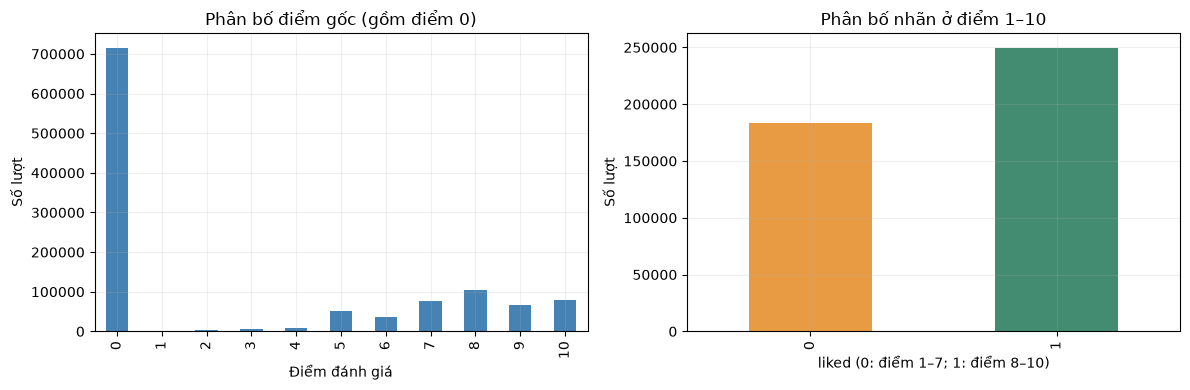

Tỷ lệ điểm 0 trong dữ liệu gốc: 62.28%
Tỷ lệ liked = 1 trong tập phân loại: 57.62%


In [94]:
# Điểm 0 chỉ xuất hiện ở biểu đồ dữ liệu tổng hợp, không dùng để tạo nhãn không thích.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ratings_clean["Book-Rating"].value_counts().reindex(range(11), fill_value=0).plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Phân bố điểm gốc (gồm điểm 0)", xlabel="Điểm đánh giá", ylabel="Số lượt")
label_summary["Số lượt"].plot.bar(ax=axes[1], color=["#e99b44", "#438c72"])
axes[1].set(title="Phân bố nhãn ở điểm 1–10", xlabel="liked (0: điểm 1–7; 1: điểm 8–10)", ylabel="Số lượt")
finish_figure("01_ratings_and_labels.png")
print("Tỷ lệ điểm 0 trong dữ liệu gốc:", f"{ratings_clean['Book-Rating'].eq(0).mean():.2%}")
print("Tỷ lệ liked = 1 trong tập phân loại:", f"{classification_data['liked'].mean():.2%}")

### 4.3. Phân bố tuổi, năm và các giá trị bất thường
Dùng bảng người dùng/sách riêng để mỗi người hoặc sách chỉ được đếm một lần. Nếu dùng bảng ghép, một người có nhiều đánh giá sẽ được lặp nhiều lần. Các giá trị ngoài ngưỡng đã được đổi thành thiếu ở phần 3; chưa điền trung vị khi vẽ.

,Age
count,166848.0
mean,34.746638
std,13.633051
min,5.0
25%,24.0
50%,32.0
75%,44.0
max,100.0


,Year-Of-Publication
count,266726.0
mean,1993.692692
std,8.148499
min,1806.0
25%,1989.0
50%,1996.0
75%,2000.0
max,2026.0


Tuổi có số nhưng ngoài 5–100: 1248
Năm có số nhưng ngoài 1450–2026 (gồm năm 0): 4631


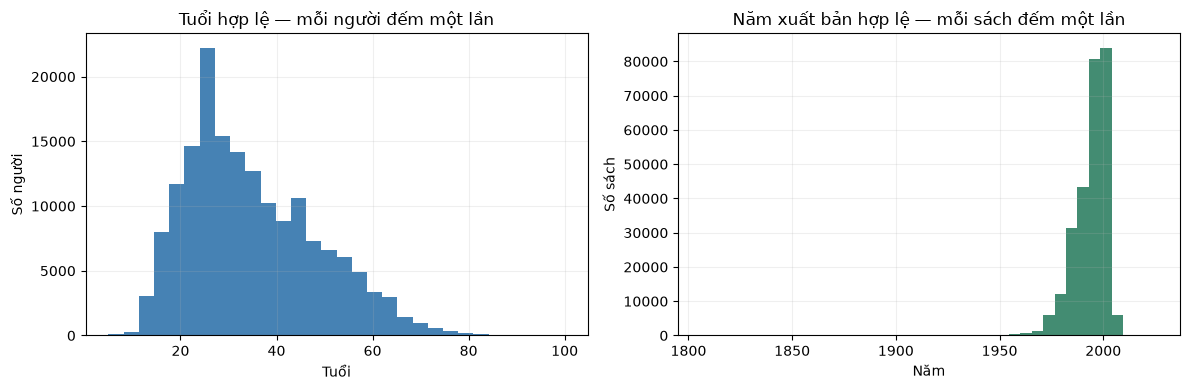

In [95]:
# Mô tả tuổi và năm sau làm sạch, đồng thời đếm các giá trị ngoài ngưỡng ở dữ liệu gốc.
display(users_clean[["Age"]].describe())
display(books_clean[["Year-Of-Publication"]].describe())
raw_age = pd.to_numeric(users["Age"], errors="coerce")
raw_year = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")
print("Tuổi có số nhưng ngoài 5–100:", (raw_age.notna() & ~raw_age.between(5, 100)).sum())
print("Năm có số nhưng ngoài 1450–2026 (gồm năm 0):", (raw_year.notna() & ~raw_year.between(1450, 2026)).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
users_clean["Age"].dropna().astype(float).plot.hist(bins=30, ax=axes[0], color="steelblue")
axes[0].set(title="Tuổi hợp lệ — mỗi người đếm một lần", xlabel="Tuổi", ylabel="Số người")
books_clean["Year-Of-Publication"].dropna().astype(float).plot.hist(bins=40, ax=axes[1], color="#438c72")
axes[1].set(title="Năm xuất bản hợp lệ — mỗi sách đếm một lần", xlabel="Năm", ylabel="Số sách")
finish_figure("02_age_and_year.png")

### 4.4. Mối liên hệ với nhãn và mức độ tập trung đánh giá
Tỷ lệ thích theo nhóm tuổi có kèm số lượt để tránh diễn giải quá mức các nhóm ít mẫu. Số lượt không phải số người độc lập: một người có thể đánh giá nhiều sách. Ma trận tương quan Pearson chỉ mô tả liên hệ tuyến tính; tương quan thấp không chứng minh đặc trưng vô ích với mọi mô hình.

,So_luot,Ty_le_thich
Age_group,,
5–17,10879,0.606122
18–29,88741,0.593153
30–44,127101,0.585912
45–59,63614,0.638507
60–100,12765,0.609244
Thiếu tuổi,130571,0.519189


,Age,Year-Of-Publication,liked
Age,1.000,0.025,0.031
Year-Of-Publication,0.025,1.000,-0.001
liked,0.031,-0.001,1.000


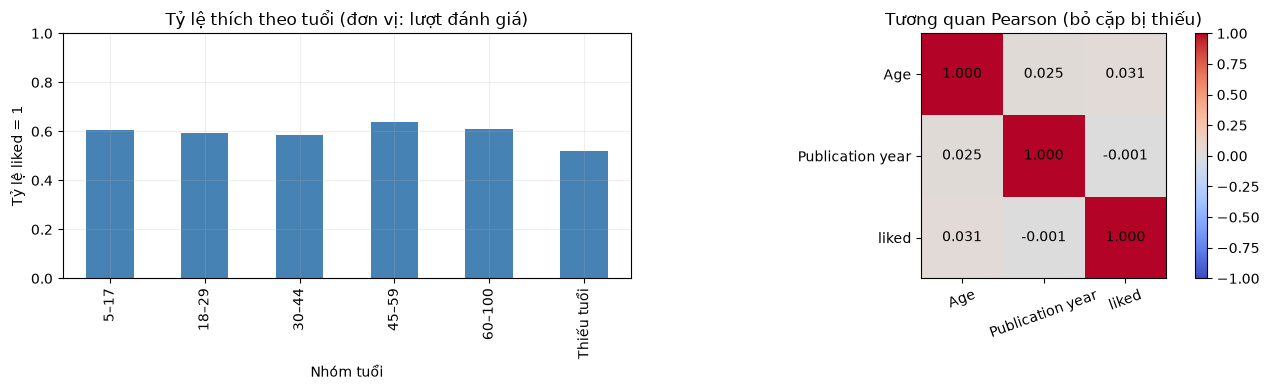

,So_luot,Ty_le_thich,Book-Title
ISBN,,,
0316666343,707,0.728430,The Lovely Bones: A Novel
0971880107,581,0.113597,Wild Animus
0385504209,487,0.767967,The Da Vinci Code
0312195516,383,0.725849,The Red Tent (Bestselling Backlist)
0679781587,333,0.771772,<NA>
0060928336,320,0.665625,Divine Secrets of the Ya-Ya Sisterhood: A Novel
059035342X,313,0.881789,Harry Potter and the Sorcerer's Stone (Harry P...
0142001740,307,0.791531,The Secret Life of Bees
0446672211,295,0.732203,Where the Heart Is (Oprah's Book Club (Paperba...


Số lượt đánh giá mỗi người — trung vị: 1.0 ; lớn nhất: 8524
Số giá trị phân biệt ở các cột chữ:


,Số giá trị
Book-Author,62111
Publisher,11574
Location,21335


In [96]:
# Chia tuổi thành nhóm; giữ riêng người thiếu tuổi để không làm mất họ trong thống kê.
age_group = pd.cut(classification_data["Age"].astype(float),
                   bins=[5, 18, 30, 45, 60, 101], right=False,
                   labels=["5–17", "18–29", "30–44", "45–59", "60–100"])
age_group = age_group.astype("string").fillna("Thiếu tuổi")
age_target = (classification_data.assign(Age_group=age_group)
              .groupby("Age_group", observed=True)["liked"]
              .agg(So_luot="size", Ty_le_thich="mean")
              .reindex(["5–17", "18–29", "30–44", "45–59", "60–100", "Thiếu tuổi"]))
display(age_target)

# Chuyển dữ liệu nullable sang float để tính và vẽ tương quan số.
corr = classification_data[["Age", "Year-Of-Publication", "liked"]].astype(float).corr()
display(corr.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
age_target["Ty_le_thich"].plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Tỷ lệ thích theo tuổi (đơn vị: lượt đánh giá)", xlabel="Nhóm tuổi", ylabel="Tỷ lệ liked = 1", ylim=(0, 1))
image = axes[1].imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
names = ["Age", "Publication year", "liked"]
axes[1].set_xticks(range(3), names, rotation=20)
axes[1].set_yticks(range(3), names)
axes[1].set_title("Tương quan Pearson (bỏ cặp bị thiếu)")
axes[1].grid(False)
for row in range(3):
    for col in range(3):
        axes[1].text(col, row, f"{corr.iloc[row, col]:.3f}", ha="center", va="center")
fig.colorbar(image, ax=axes[1])
finish_figure("03_age_target_and_correlation.png")

# Tìm các sách được đánh giá nhiều, không đồng nhất mức phổ biến với mức được yêu thích.
top_books = (classification_data.groupby("ISBN")
             .agg(So_luot=("liked", "size"), Ty_le_thich=("liked", "mean")))
top_books = top_books.join(books_clean.set_index("ISBN")[["Book-Title"]]).nlargest(10, "So_luot")
display(top_books)
user_activity = classification_data.groupby("User-ID").size()
print("Số lượt đánh giá mỗi người — trung vị:", user_activity.median(), "; lớn nhất:", user_activity.max())
print("Số giá trị phân biệt ở các cột chữ:")
display(classification_data[["Book-Author", "Publisher", "Location"]].nunique().rename("Số giá trị").to_frame())

### 4.5. Nhận xét và quyết định đặc trưng
Kết quả từ lần chạy với dữ liệu hiện tại (các ô thống kê phía trên sẽ cập nhật khi Run All): điểm 0 chiếm **62,28%** tổng lượt đánh giá; sau khi chỉ giữ điểm 1–10, nhãn thích chiếm **57,62%**. Có **11,49%** lượt trong tập phân loại chưa có metadata sách sạch. Tương quan Pearson của tuổi với liked khoảng **0,031**, của năm xuất bản với liked khoảng **−0,001**: liên hệ tuyến tính quan sát được rất yếu. Đây là thống kê mô tả, không phải bằng chứng nhân quả.

- Tuổi 244 không được coi là tuổi hợp lệ: các giá trị ngoài ngưỡng trở thành thiếu và có cờ thiếu. Không thay tuổi bằng trung vị trên toàn bộ dữ liệu.
- Điểm 0 và việc thiếu metadata sách cần được phân biệt với nhãn không thích. Giữ đánh giá thiếu thông tin sách để tránh chỉ phân tích sách ghép được.
- Tuổi và năm có thể có liên hệ yếu với liked; vẫn giữ làm ứng viên vì chi phí xử lý thấp. Tác giả, nhà xuất bản và quốc gia bổ sung thông tin phân loại. Thống kê mô tả ở trên không đủ để kết luận yếu tố nào gây ra sở thích.
- Các cột chữ có nhiều giá trị phân biệt; giới hạn số nhóm one-hot để tiết kiệm bộ nhớ và giảm ảnh hưởng nhóm hiếm. Bỏ tên sách ở phiên bản cơ sở. Country được tách từ Location bằng quy tắc đơn giản nên chưa được xem là quốc gia đã xác thực.
- Không dùng điểm đánh giá, mã người dùng hay mã sách làm đầu vào. Dữ liệu không có thời gian đánh giá, nên chưa kiểm chứng được mô hình khi dự đoán tương lai; năm xuất bản nằm trong ngưỡng cũng chưa đảm bảo đúng về lịch sử.

## 5. Implementing Machine Learning Algorithms
### 5.1. Chia dữ liệu và chuẩn bị đặc trưng
Mục tiêu kiểm thử là dự đoán đánh giá của **người dùng chưa xuất hiện trong tập train**. Chia theo User-ID khoảng 70%/15%/15% số người dùng thành train/validation/test; tỷ lệ số dòng có thể khác vì số đánh giá mỗi người khác nhau. Một sách có thể xuất hiện ở nhiều tập. Cách chia này tránh cùng một người xuất hiện ở cả train và test, nhưng không phải đánh giá cho sách hoàn toàn mới.

Tập validation dùng để so sánh các cấu hình đã định trước; tập test được giữ riêng cho phần 6. Median, nhóm danh mục hiếm, one-hot và chuẩn hóa đều chỉ fit trên train qua Pipeline. Không dùng toàn bộ dữ liệu để điền thiếu hoặc học danh mục.

In [97]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.base import clone
from time import perf_counter

RANDOM_STATE = 42

# Chỉ tạo đặc trưng bằng quy tắc cố định; không học thống kê từ toàn bộ dữ liệu.
model_data = classification_data.copy()
model_data["Country"] = (model_data["Location"].astype("string")
                         .str.rsplit(",", n=1).str[-1].str.strip().str.lower()
                         .replace("", pd.NA).fillna("unknown"))
model_data["Book_metadata_missing"] = model_data["book_match"].eq("left_only").astype("int8")

# Cờ năm thiếu bao gồm cả trường hợp không ghép được sách (Year_missing khi đó có thể là NA).
model_data["Year_missing"] = model_data["Year-Of-Publication"].isna().astype("int8")
model_data["Age_missing"] = model_data["Age"].isna().astype("int8")
numeric_features = ["Age", "Year-Of-Publication"]
flag_features = ["Age_missing", "Year_missing", "Book_metadata_missing"]
categorical_features = ["Book-Author", "Publisher", "Country"]
feature_columns = numeric_features + flag_features + categorical_features
X = model_data[feature_columns].copy()
y = model_data["liked"].astype("int8")
groups = model_data["User-ID"]

# Chuyển nullable pandas sang kiểu mà các bộ tiền xử lý sklearn tiếp nhận rõ ràng.
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)
for col in categorical_features:
    X[col] = X[col].astype("string").fillna("Unknown").astype(object)

# Tách test trước; tiếp tục chia train/validation chỉ trong phần còn lại.
split_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=RANDOM_STATE)
train_valid_idx, test_idx = next(split_test.split(X, y, groups=groups))
split_valid = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=RANDOM_STATE + 1)
train_rel, valid_rel = next(split_valid.split(X.iloc[train_valid_idx], y.iloc[train_valid_idx],
                                            groups=groups.iloc[train_valid_idx]))
train_idx, valid_idx = train_valid_idx[train_rel], train_valid_idx[valid_rel]
X_train, X_valid, X_test = X.iloc[train_idx], X.iloc[valid_idx], X.iloc[test_idx]
y_train, y_valid, y_test = y.iloc[train_idx], y.iloc[valid_idx], y.iloc[test_idx]

# Xác minh người dùng không chồng lấn và các tập đều có đủ hai lớp.
user_sets = [set(groups.iloc[idx]) for idx in [train_idx, valid_idx, test_idx]]
assert user_sets[0].isdisjoint(user_sets[1])
assert user_sets[0].isdisjoint(user_sets[2])
assert user_sets[1].isdisjoint(user_sets[2])
assert all(target.nunique() == 2 for target in [y_train, y_valid, y_test])
assert "Book-Rating" not in X.columns and "liked" not in X.columns
split_summary = pd.DataFrame([
    {"Tập": name, "Số lượt": len(idx), "Số người": groups.iloc[idx].nunique(),
     "Tỷ lệ thích": y.iloc[idx].mean()}
    for name, idx in [("Train", train_idx), ("Validation", valid_idx), ("Test", test_idx)]
])
display(split_summary)

,Tập,Số lượt,Số người,Tỷ lệ thích
0,Train,305357,54463,0.574220
1,Validation,62803,11671,0.589001
2,Test,65511,11671,0.573247


### 5.2. Pipeline và mô hình
**DummyClassifier** luôn dự đoán lớp phổ biến nhất trong train, làm mốc so sánh. **Logistic Regression** là mô hình tuyến tính cho xác suất thuộc lớp thích. **Decision Tree** học quy tắc chia nhánh và có thể biểu diễn liên hệ phi tuyến; giới hạn độ sâu và số mẫu mỗi lá để hạn chế học thuộc.

Với cột số: điền median từ train rồi chuẩn hóa. Với cột chữ: one-hot dạng sparse; mỗi cột có tối đa 150 nhóm (gồm nhóm hiếm), ngưỡng nhóm hiếm 50 mẫu được tính chỉ từ train. Giá trị mới được xử lý bằng `handle_unknown="infrequent_if_exist"`. Cờ thiếu giữ dạng 0/1. Cấu hình này ưu tiên chạy được trên Colab, chưa phải tối ưu siêu tham số đầy đủ.

In [98]:
# Định nghĩa bộ tiền xử lý; chưa fit ở bước khai báo này.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50,
                              max_categories=150, sparse_output=True, dtype=np.float64)),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("flags", "passthrough", flag_features),
    ("category", categorical_pipeline, categorical_features),
], sparse_threshold=1.0)

# Mỗi mô hình có bản sao bộ tiền xử lý riêng; fit toàn bộ pipeline chỉ trên train.
models = {
    "Baseline (most frequent)": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", DummyClassifier(strategy="most_frequent")),
    ]),
    "Logistic Regression": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", LogisticRegression(C=1.0, solver="liblinear", max_iter=500,
                                     random_state=RANDOM_STATE)),
    ]),
    "Decision Tree": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", DecisionTreeClassifier(max_depth=12, min_samples_leaf=100,
                                         random_state=RANDOM_STATE)),
    ]),
}

# Huấn luyện và so sánh sơ bộ bằng validation; chưa dự đoán trên test.
validation_rows = []
for name, model in models.items():
    started = perf_counter()
    model.fit(X_train, y_train)
    predictions = model.predict(X_valid)
    positive_index = list(model.classes_).index(1)
    probabilities = model.predict_proba(X_valid)[:, positive_index]
    validation_rows.append({
        "Mô hình": name,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_valid, predictions),
        "F1 macro": f1_score(y_valid, predictions, average="macro", zero_division=0),
        "ROC AUC": roc_auc_score(y_valid, probabilities),
        "Thời gian (s)": perf_counter() - started,
    })
validation_results = (pd.DataFrame(validation_rows).set_index("Mô hình")
                      .sort_values("F1 macro", ascending=False))
display(validation_results.round(4))

# Chọn theo F1 macro để cả hai lớp đều có trọng số ngang nhau; baseline vẫn có thể thắng.
best_model_name = validation_results.index[0]
best_model = models[best_model_name]
print("Mô hình có F1 macro validation cao nhất:", best_model_name)
print("Số cột sau mã hóa:", len(best_model.named_steps["preprocess"].get_feature_names_out()))

,Accuracy,Balanced accuracy,F1 macro,ROC AUC,Thời gian (s)
Mô hình,,,,,
Logistic Regression,0.5936,0.5323,0.4965,0.5817,4.1406
Decision Tree,0.5931,0.5154,0.4357,0.5573,1.8492
Baseline (most frequent),0.5890,0.5000,0.3707,0.5000,1.0665


Mô hình có F1 macro validation cao nhất: Logistic Regression
Số cột sau mã hóa: 356


### 5.3. Minh họa dự đoán và lưu kết quả cho bước đánh giá
Các dự đoán minh họa lấy từ validation, không phải test. Xác suất là đầu ra của mô hình, chưa được kiểm định hiệu chỉnh xác suất. Không kết luận mô hình tốt chỉ từ accuracy; bảng trên chỉ dùng chọn mô hình trước bước đánh giá độc lập ở phần 6.

In [99]:
# Minh họa 10 dòng ở validation; nhãn thật chỉ dùng đối chiếu sau dự đoán.
example = X_valid.head(10).copy()
positive_index = list(best_model.classes_).index(1)
example["Nhãn thật"] = y_valid.head(10).to_numpy()
example["Nhãn dự đoán"] = best_model.predict(X_valid.head(10))
example["Xác suất thích"] = best_model.predict_proba(X_valid.head(10))[:, positive_index]
display(example)

# Lưu thống kê, kết quả và danh sách chia tập để dùng lại trong báo cáo/phần 6.
OUTPUT_DIR = Path("outputs")
validation_results.to_csv(OUTPUT_DIR / "validation_results.csv", encoding="utf-8-sig")
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False, encoding="utf-8-sig")
split_assignment = model_data[["User-ID", "ISBN"]].copy()
split_assignment["Split"] = ""
for name, idx in [("train", train_idx), ("validation", valid_idx), ("test", test_idx)]:
    split_assignment.iloc[idx, split_assignment.columns.get_loc("Split")] = name
split_assignment.to_csv(OUTPUT_DIR / "split_assignment.csv", index=False)

baseline_f1 = validation_results.loc["Baseline (most frequent)", "F1 macro"]
best_f1 = validation_results.loc[best_model_name, "F1 macro"]
print(f"F1 macro validation: baseline = {baseline_f1:.4f}; cao nhất = {best_f1:.4f}.")
print("Mức tăng F1 macro so với baseline:", f"{best_f1 - baseline_f1:.4f}")
print("Đã lưu biểu đồ và kết quả trong:", OUTPUT_DIR.resolve())
print("Tập test chưa được dùng để chấm điểm hoặc chọn mô hình.")

,Age,Year-Of-Publication,Age_missing,Year_missing,Book_metadata_missing,Book-Author,Publisher,Country,Nhãn thật,Nhãn dự đoán,Xác suất thích
30,25.0,NaN,0,1,1,Unknown,Unknown,spain,1,0,0.431556
69,18.0,NaN,0,1,1,Unknown,Unknown,spain,0,0,0.421994
70,18.0,NaN,0,1,1,Unknown,Unknown,spain,0,0,0.421994
118,29.0,1998.0,0,0,0,Rosa Montero,"Espasa Calpe Mexicana, S.A.",spain,1,0,0.462840
120,29.0,1996.0,0,0,0,Helen Fielding,Lumen Espana,spain,1,0,0.454956
121,29.0,2000.0,0,0,0,Helen Fielding,Downtown Book Center Inc,spain,0,0,0.458241
122,29.0,NaN,0,1,1,Unknown,Unknown,spain,1,0,0.437043
123,29.0,NaN,0,1,0,Lisa Jewell,Emece Editores,spain,0,0,0.467028
124,29.0,NaN,0,1,1,Unknown,Unknown,spain,0,0,0.437043
125,29.0,2001.0,0,0,0,Jane Green,Oceano De Mexico,spain,1,0,0.465311


F1 macro validation: baseline = 0.3707; cao nhất = 0.4965.
Mức tăng F1 macro so với baseline: 0.1258
Đã lưu biểu đồ và kết quả trong: /mnt/BACKUP/FDA/PTDL_PY/midterm_material/outputs
Tập test chưa được dùng để chấm điểm hoặc chọn mô hình.


### Sẵn sàng cho phần 6
`models` chứa ba pipeline đã fit trên train; `best_model` là pipeline đứng đầu theo F1 macro validation. `X_test`, `y_test` dành cho đánh giá cuối cùng. Phần 6 cần bổ sung confusion matrix, precision/recall/F1 theo lớp và đường ROC trên test, đồng thời so với baseline. Nếu điều chỉnh cấu hình, chỉ dùng train/validation; không tối ưu theo test.

Các mô hình hiện tại chỉ khai thác thông tin người dùng và sách, chưa học lịch sử tương tác cá nhân như hệ gợi ý cộng tác. Cách chia theo người dùng mới là một giới hạn cần nêu trong báo cáo. Nhóm hiếm được gộp và Location chưa chuẩn hóa địa lý đầy đủ cũng có thể làm giảm chất lượng. Mọi nhận định về hiệu quả cần dựa trên kết quả chạy thực tế, không cam kết trước mô hình nào sẽ tốt nhất.

Kết quả lần chạy hiện tại: Logistic Regression đứng đầu trên validation với **F1 macro = 0,4965**, so với **0,3707** của baseline và **0,4357** của Decision Tree. Accuracy lần lượt khoảng **59,36%**, **58,90%** và **59,31%**; ROC AUC của Logistic Regression khoảng **0,5817**. Mức phân biệt còn thấp và cải thiện accuracy nhỏ, nên chưa thể kết luận mô hình đủ tốt cho ứng dụng thực tế. Các số này là kết quả validation của cấu hình hiện tại, cần cập nhật nếu dữ liệu hoặc cấu hình thay đổi; chưa phải kết quả test.
